# Prédiction de l'accès à la fibre optique (FTTH) au Togo

<p align="center">
  <img src="../docs/images/tog.jpg" alt="Fibre optique au Togo" width="420"/>
</p>

---

## Contexte du projet

Ce projet vise à prédire l'accès à la fibre optique jusqu'au domicile
(*FTTH – Fiber to the Home*) pour les ménages au Togo.

En combinant des **données socio-démographiques** (recensement RGPH) et des **features géospatiales MOSAIKS issues d'images satellites**, nous développons des modèles de *machine learning* capables d'estimer la probabilité d'accès de chaque ménage et d'orienter les décisions de déploiement.

## Objectifs du projet

- Analyser les facteurs socio-économiques et territoriaux liés à l'accès FTTH
- Estimer la probabilité d'accès FTTH pour chaque ménage
- Identifier les zones prioritaires pour le déploiement de la fibre
- **Mesurer honnêtement** la fiabilité du modèle, y compris sur des zones jamais observées

## Organisation du code

La logique réutilisable (nettoyage, prétraitement, modèles, évaluation, export) se trouve dans le package
[`src/ftth_access`](../src/ftth_access) et est testée (`pytest`). Ce notebook raconte l'analyse et s'appuie sur ce package ;
la commande `ftth-train` reproduit le même protocole en ligne de commande.
Les limites de la version précédente et leurs corrections sont détaillées dans [`docs/AUDIT.md`](../docs/AUDIT.md).

## I. Configuration

- **pandas, numpy** : manipulation des données
- **matplotlib, seaborn** : visualisations
- **scikit-learn, xgboost, lightgbm** : prétraitement, modèles et validation
- **shap** : interprétabilité
- **ftth_access** : package du projet (`src/`)

In [1]:
import sys
from pathlib import Path

# Permet d'exécuter le notebook sans installation préalable du package (`pip install -e .`).
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.decomposition import PCA
from sklearn.metrics import ConfusionMatrixDisplay, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import Pipeline

from ftth_access import data, evaluation, features, models, train
from ftth_access.config import CV_FOLDS, OUTPUT_DIR, RANDOM_STATE, TARGET_COL, TEST_SIZE

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.4f}".format)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 100
OUTPUT_DIR.mkdir(exist_ok=True)

N_SEARCH_ITER = 15  # essais de recherche aléatoire d'hyperparamètres
SHAP_SAMPLE = 300   # ménages du test expliqués par SHAP


def save(fig, name):
    fig.savefig(OUTPUT_DIR / name, dpi=150, bbox_inches="tight")


print(f"Random state : {RANDOM_STATE} | Test : {TEST_SIZE:.0%} | CV : {CV_FOLDS} plis")
print(f"Sorties : {OUTPUT_DIR}")

Random state : 45 | Test : 20% | CV : 5 plis
Sorties : /home/user/ACDS_FBER_ACCESS_PRED/Output


## II. Chargement des données

Le fichier `Data/Data.parquet` (150 Mo, versionné avec Git LFS) contient 30 558 ménages × 4 043 colonnes.
`data.load_raw` vérifie qu'il ne s'agit pas d'un simple pointeur LFS (cas d'un clone sans `git lfs pull`)
et, si seul `Data.csv` est présent, crée automatiquement la version Parquet.

In [2]:
df_raw = data.load_raw()
print(f"Dimensions : {df_raw.shape[0]:,} ménages × {df_raw.shape[1]:,} colonnes")
print(f"Mémoire    : {df_raw.memory_usage(deep=True).sum() / 1e9:.2f} Go")
df_raw.iloc[:5, :12]

Dimensions : 30,558 ménages × 4,043 colonnes
Mémoire    : 1.00 Go


,ID,TypeLogmt_1,TypeLogmt_2,TypeLogmt_3,H08_Impute,H09_Impute,TAILLE_MENAGE,H17A,H17B,H17C,H17D,H17E
0,ID_88M0FMHZAM,Logement semi-moderne,Plusieurs logement,Logement � un niveau (plain-pied),Electricit� (CEET) compteur dans la concession,Gaz,1.0000,Non,Oui,Non,Non,Non
1,ID_8BRUVGMYT4,Logement semi-moderne,Plusieurs logement,Logement � un niveau (plain-pied),Electricit� (CEET) compteur dans la concession,Gaz,4.0000,Non,Oui,Non,Non,Non
2,ID_BLWKMPQSDG,Logement moderne,Plusieurs logement,Logement � un niveau (plain-pied),Electricit� (CEET) compteur dans la concession,Charbon de bois,1.0000,Non,Non,Non,Non,Non
3,ID_5FF71INFJ2,Logement moderne,Plusieurs logement,Logement ? un niveau (plain-pied),Electricit? (CEET) compteur dans la concession,Gaz,4.0000,Non,Non,Non,Non,Non
4,ID_BL1YKKNQ4Y,Logement moderne,Plusieurs logement,Logement � un niveau (plain-pied),Electricit� (CEET) compteur dans la concession,Charbon de bois,1.0000,Non,Non,Non,Non,Non


## III. Qualité des données : cinq problèmes à traiter

### 1. Accents corrompus dans les libellés
Selon les lignes, les caractères accentués ont été remplacés par `�` ou par `?`. Une même modalité apparaît
donc sous plusieurs formes, ce qui crée de fausses catégories.

In [3]:
print(df_raw["TypeLogmt_3"].value_counts(), "\n")
print("Nombre de modalités brutes :")
print(df_raw[["TypeLogmt_1", "TypeLogmt_2", "TypeLogmt_3", "H08_Impute", "H09_Impute"]].nunique())

TypeLogmt_3
Logement � un niveau (plain-pied)         19733
Logement ? un niveau (plain-pied)          7237
Logement � plusieurs niveaux (� �tage)     2184
Logement ? plusieurs niveaux (? ?tage)     1239
Autre                                       165
Name: count, dtype: int64 

Nombre de modalités brutes :
TypeLogmt_1     4
TypeLogmt_2     3
TypeLogmt_3     5
H08_Impute     17
H09_Impute     13
dtype: int64


### 2. Noms de colonnes MOSAIKS
Dans le CSV d'origine, les 4 000 en-têtes MOSAIKS sont vides ; pandas les a dédoublonnés en `" "`, `" .1"`, …, `" .3999"`.
La colonne `" "` est donc la **feature MOSAIKS n°0** (et non une colonne parasite) : elle doit être traitée avec les autres.

### 3. Colonnes inutilisables comme features
- `BoxLabel` ne prend qu'une seule valeur ;
- `Connexion` (opérateur) est manquante **si et seulement si** le ménage n'a pas accès à la fibre :
  c'est une **fuite de la cible**, elle doit être exclue.

In [4]:
mosaiks_raw = [c for c in df_raw.columns if c.strip() == "" or c.startswith(" .")]
print(f"Colonnes MOSAIKS : {len(mosaiks_raw)} (de {mosaiks_raw[0]!r} à {mosaiks_raw[-1]!r})")
print(f"BoxLabel : {df_raw['BoxLabel'].unique().tolist()}\n")
pd.crosstab(df_raw["Connexion"].fillna("Manquant"), df_raw[TARGET_COL], margins=True)

Colonnes MOSAIKS : 4000 (de ' ' à ' .3999')
BoxLabel : ['Box0']



Accès internet,0.0000,1.0000,All
Connexion,,,
GVA,2645,7775,10420
Manquant,10508,0,10508
Togocom,2497,7133,9630
All,15650,14908,30558


### 4. Les features MOSAIKS décrivent des tuiles, pas des ménages
Les ménages d'une même tuile satellite partagent **exactement** le même vecteur MOSAIKS.
Le jeu de données ne contient en réalité qu'**environ 400 tuiles distinctes** : c'est déterminant pour l'évaluation (section XI).

### 5. Valeurs manquantes
Hormis `Connexion` (exclue), aucune feature ne contient de valeur manquante.

Tuiles satellite distinctes : 423 pour 30,558 ménages


Valeurs manquantes dans les features : 0


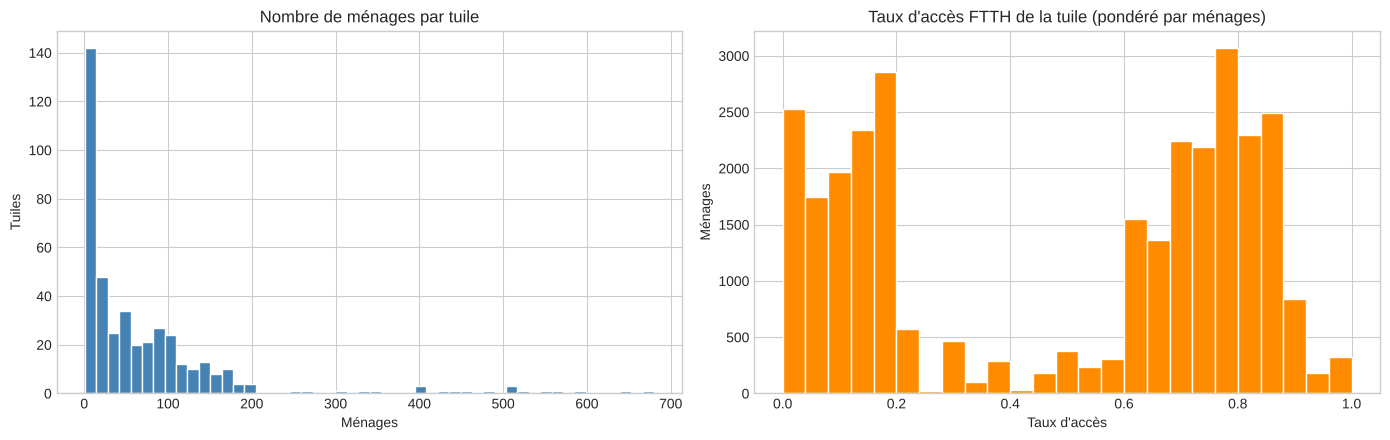

In [5]:
df = data.clean(df_raw)
del df_raw

tiles = data.tile_ids(df)
features_cols = data.feature_groups(df.columns).all
print(f"Tuiles satellite distinctes : {tiles.nunique()} pour {len(df):,} ménages")
print(f"Valeurs manquantes dans les features : {int(df[features_cols].isna().sum().sum())}")

tile_stats = df.groupby(tiles)[TARGET_COL].agg(["size", "mean"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(tile_stats["size"], bins=50, color="steelblue", edgecolor="white")
axes[0].set(title="Nombre de ménages par tuile", xlabel="Ménages", ylabel="Tuiles")
axes[1].hist(tile_stats["mean"], bins=25, weights=tile_stats["size"], color="darkorange", edgecolor="white")
axes[1].set(title="Taux d'accès FTTH de la tuile (pondéré par ménages)", xlabel="Taux d'accès", ylabel="Ménages")
plt.tight_layout()
save(fig, "tiles_distribution.png")
plt.show()

## IV. Nettoyage

`data.clean` :
- ramène chaque libellé à sa forme française correcte (clé alphanumérique commune à toutes les variantes corrompues) ;
- **ne modifie jamais la colonne `ID`** (la version précédente supprimait le `_` des identifiants, ce qui empêchait toute jointure avec les données d'origine) ;
- renomme les colonnes MOSAIKS en `mosaiks_0` … `mosaiks_3999` et les convertit en `float32` (mémoire divisée par deux) ;
- encode explicitement les équipements `Oui`/`Non` en 1/0 et refuse toute valeur inattendue.

In [6]:
for col in ["TypeLogmt_1", "TypeLogmt_3", "H08_Impute", "H09_Impute"]:
    print(df[col].value_counts().to_string(), "\n")
print("Exemples d'ID :", df["ID"].head(3).tolist())
print(f"Mémoire après nettoyage : {df.memory_usage(deep=True).sum() / 1e9:.2f} Go")

TypeLogmt_1
Logement moderne         17892
Logement semi-moderne     9122
Logement traditionnel     3379
Autre                      165 

TypeLogmt_3
Logement à un niveau (plain-pied)         26970
Logement à plusieurs niveaux (à étage)     3423
Autre                                       165 

H08_Impute
Électricité CEET (compteur dans la concession)    24040
Électricité CEET (compteur hors concession)        3809
Câblage d'électricité du voisinage                 1570
Torche/bougie                                       698
Autre                                               213
Lampe à pétrole                                      85
Énergie solaire                                      70
Lampion                                              45
Groupe électrogène                                   19
Lampe à gaz                                           9 

H09_Impute
Charbon de bois                    17277
Gaz                                10673
Bois de chauffe                     11

## V. Analyse exploratoire

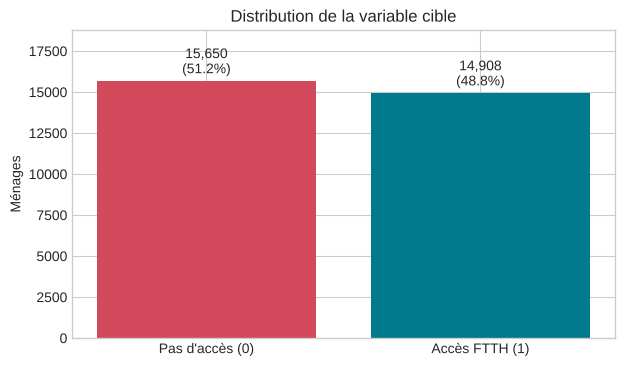

Ratio : 1.05:1 -> classes équilibrées, aucun rééquilibrage nécessaire.


In [7]:
counts = df[TARGET_COL].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(["Pas d'accès (0)", "Accès FTTH (1)"], counts.values, color=["#d1495b", "#00798c"])
ax.bar_label(bars, labels=[f"{v:,}\n({v / counts.sum():.1%})" for v in counts.values], padding=3)
ax.set(title="Distribution de la variable cible", ylabel="Ménages", ylim=(0, counts.max() * 1.2))
save(fig, "target_distribution.png")
plt.show()
print(f"Ratio : {counts[0] / counts[1]:.2f}:1 -> classes équilibrées, aucun rééquilibrage nécessaire.")

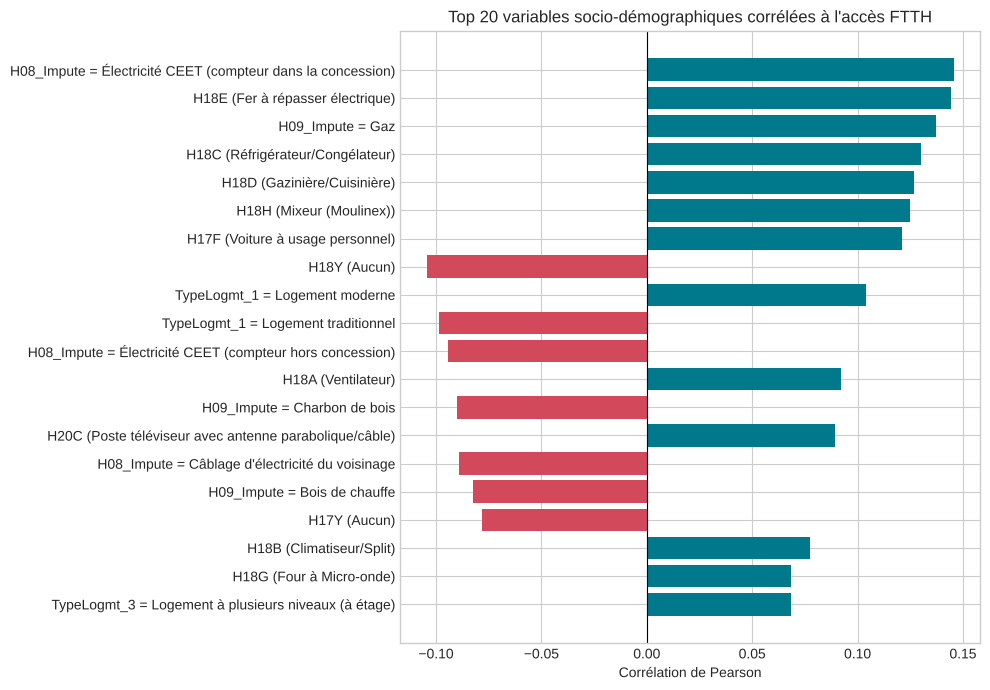

In [8]:
groups = data.feature_groups(df.columns)
socio = pd.concat(
    [pd.get_dummies(df[groups.nominal], prefix_sep=" = ", dtype=float), df[groups.numeric + groups.binary]],
    axis=1,
)
correlations = socio.corrwith(df[TARGET_COL]).sort_values(key=np.abs, ascending=False)

labels = data.load_variable_labels()  # dictionnaire des variables (Data/metadonnees.csv)


def display_name(col, width=48):
    # Nom lisible : "H18C (Réfrigérateur/Congélateur)", "TypeLogmt_1 = Logement moderne".
    for nominal in groups.nominal:
        if col.startswith(nominal + "_"):
            name = f"{nominal} = {col[len(nominal) + 1:]}"
            break
    else:
        name = f"{col} ({labels[col]})" if col in labels else col
    return name if len(name) <= width else name[: width - 1] + "…"


top = correlations.head(20)
top.index = [display_name(c, width=60) for c in top.index]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top.index[::-1], top.values[::-1], color=np.where(top.values[::-1] > 0, "#00798c", "#d1495b"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Top 20 variables socio-démographiques corrélées à l'accès FTTH", xlabel="Corrélation de Pearson")
plt.tight_layout()
save(fig, "top_correlations.png")
plt.show()

**Lecture** : l'accès FTTH est associé à un ménage raccordé à l'électricité dans sa concession, cuisinant au gaz et équipé
en électroménager (fer à repasser électrique, réfrigérateur, gazinière, mixeur) ou d'une voiture ; à l'inverse, l'absence
d'électroménager (`H18Y`), le logement traditionnel, le compteur hors concession et la cuisson au charbon ou au bois y sont
négativement liés. Toutes ces corrélations restent **faibles (|r| ≤ 0,15)** : les variables socio-démographiques seules
prédisent mal l'accès.

## VI. Split train/test officiel

Contrainte du challenge : split 80/20 **stratifié** avec `random_state=45`.
Le jeu de test n'est utilisé **qu'une seule fois**, pour l'évaluation finale : le choix du modèle et des hyperparamètres se fait
par validation croisée sur le train.

In [9]:
ds = train.split_dataset(df)
X_train, X_test, y_train, y_test = ds.X_train, ds.X_test, ds.y_train, ds.y_test

print(f"Train : {len(X_train):,} ménages ({y_train.mean():.2%} avec accès)")
print(f"Test  : {len(X_test):,} ménages ({y_test.mean():.2%} avec accès)")
seen = np.isin(ds.groups_test, ds.groups_train).mean()
print(f"Ménages du test situés dans une tuile déjà vue au train : {seen:.2%}")

Train : 24,446 ménages (48.79% avec accès)
Test  : 6,112 ménages (48.79% avec accès)
Ménages du test situés dans une tuile déjà vue au train : 99.93%


## VII. Prétraitement : un pipeline scikit-learn unique

`features.build_preprocessor` regroupe tout le prétraitement dans un `ColumnTransformer` appris **sur le train uniquement**
et sauvegardé avec le modèle (la version précédente standardisait « à la main » sans sauvegarder les paramètres :
le modèle exporté était inutilisable sur de nouvelles données).

| Groupe | Colonnes | Traitement |
|---|---|---|
| Nominales | type de logement, éclairage, cuisson | one-hot (pas d'ordre artificiel) |
| Numérique | taille du ménage | imputation médiane + standardisation |
| Équipements | 33 variables Oui/Non | 0/1 tels quels |
| MOSAIKS | 4 000 features | standardisation + PCA (95 % de variance) |

La PCA utilise le solveur `covariance_eigh` : même résultat que le solveur exact, ~30× plus rapide et sans `MemoryError`.

In [10]:
preprocessor = features.build_preprocessor(data.feature_groups(X_train.columns))
preprocessor.fit(X_train, y_train)
X_train_t = preprocessor.transform(X_train)
X_test_t = preprocessor.transform(X_test)

pca = preprocessor.named_transformers_["mosaiks"].named_steps["pca"]
print(f"Features : {X_train.shape[1]:,} brutes -> {X_train_t.shape[1]} après prétraitement")
print(f"PCA MOSAIKS : {pca.n_components_} composantes, {pca.explained_variance_ratio_.sum():.2%} de variance")
X_train_t.head()

Features : 4,039 brutes -> 69 après prétraitement
PCA MOSAIKS : 6 composantes, 95.94% de variance


,TypeLogmt_1_Autre,TypeLogmt_1_Logement moderne,TypeLogmt_1_Logement semi-moderne,TypeLogmt_1_Logement traditionnel,TypeLogmt_2_Autre,TypeLogmt_2_Logement unique,TypeLogmt_2_Plusieurs logements,TypeLogmt_3_Autre,TypeLogmt_3_Logement à plusieurs niveaux (à étage),TypeLogmt_3_Logement à un niveau (plain-pied),H08_Impute_Autre,H08_Impute_Câblage d'électricité du voisinage,H08_Impute_Groupe électrogène,H08_Impute_Lampe à gaz,H08_Impute_Lampe à pétrole,H08_Impute_Lampion,H08_Impute_Torche/bougie,H08_Impute_Électricité CEET (compteur dans la concession),H08_Impute_Électricité CEET (compteur hors concession),H08_Impute_Énergie solaire,H09_Impute_Autre,H09_Impute_Bois de chauffe,H09_Impute_Bouse d'animaux,H09_Impute_Charbon de bois,H09_Impute_Gaz,...,H18D,H18E,H18F,H18G,H18H,H18I,H18J,H18Y,H20A,H20B,H20C,H20D,H20E,H20Y,H21A,H21B,H21C,H21D,H21Y,mosaiks_pc1,mosaiks_pc2,mosaiks_pc3,mosaiks_pc4,mosaiks_pc5,mosaiks_pc6
29682,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,...,0,1,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,0,1,-18.9811,19.0212,-11.7876,16.1892,-19.6349,28.4995
28668,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,...,0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,1,-11.6562,-20.3123,11.8061,2.0403,-0.0918,-2.4366
14557,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,...,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,110.6026,23.3254,-13.6820,-10.5872,-2.3041,-6.3836
8890,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,...,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,53.0832,-26.8878,23.6470,6.7186,4.7820,-3.8735
15706,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,...,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,1,-42.1448,18.0492,30.4933,-5.2277,23.7338,3.7570


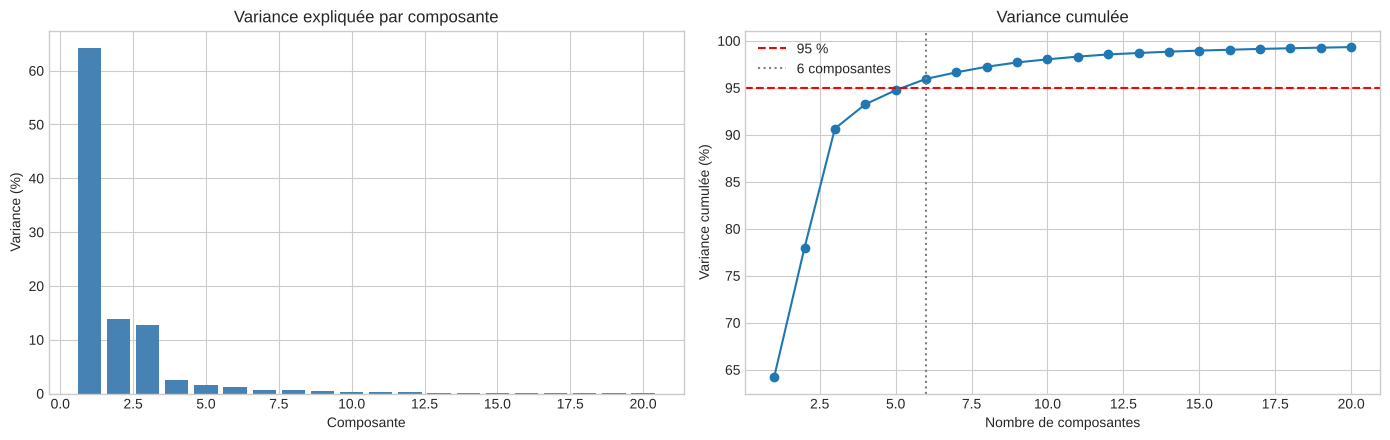

In [11]:
# Courbe de variance expliquée (PCA de visualisation à 20 composantes sur les mêmes données standardisées).
scaler = preprocessor.named_transformers_["mosaiks"].named_steps["scale"]
mosaiks_train = scaler.transform(X_train[data.mosaiks_columns(X_train.columns)])
pca20 = PCA(n_components=20, svd_solver="covariance_eigh").fit(mosaiks_train)
del mosaiks_train

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(range(1, 21), pca20.explained_variance_ratio_ * 100, color="steelblue")
axes[0].set(title="Variance expliquée par composante", xlabel="Composante", ylabel="Variance (%)")
axes[1].plot(range(1, 21), np.cumsum(pca20.explained_variance_ratio_) * 100, "o-")
axes[1].axhline(95, color="red", linestyle="--", label="95 %")
axes[1].axvline(pca.n_components_, color="grey", linestyle=":", label=f"{pca.n_components_} composantes")
axes[1].set(title="Variance cumulée", xlabel="Nombre de composantes", ylabel="Variance cumulée (%)")
axes[1].legend()
plt.tight_layout()
save(fig, "pca_variance.png")
plt.show()

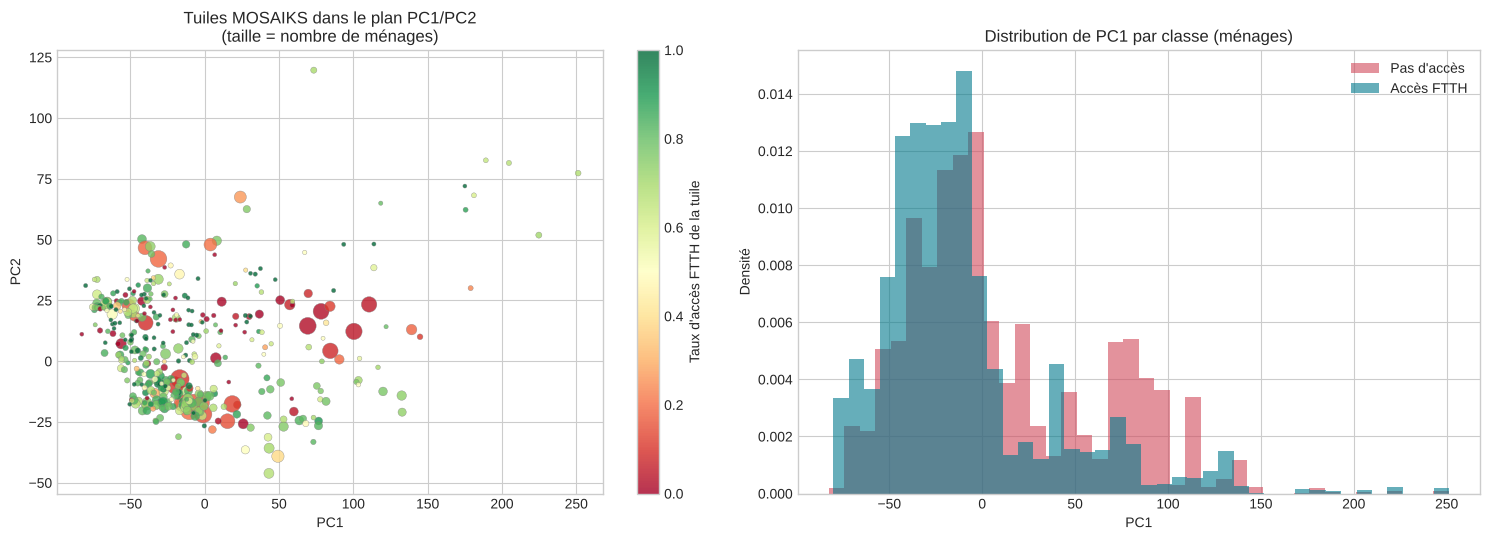

In [12]:
# Une tuile = un point (tous ses ménages ont les mêmes composantes MOSAIKS).
pcs = X_train_t[["mosaiks_pc1", "mosaiks_pc2"]].assign(tile=ds.groups_train.values, y=y_train.values)
tile_view = pcs.groupby("tile").agg(pc1=("mosaiks_pc1", "first"), pc2=("mosaiks_pc2", "first"),
                                    rate=("y", "mean"), n=("y", "size"))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sc = axes[0].scatter(tile_view["pc1"], tile_view["pc2"], c=tile_view["rate"], s=8 + tile_view["n"] / 3,
                     cmap="RdYlGn", alpha=0.8, edgecolor="grey", linewidth=0.3)
fig.colorbar(sc, ax=axes[0], label="Taux d'accès FTTH de la tuile")
axes[0].set(title="Tuiles MOSAIKS dans le plan PC1/PC2\n(taille = nombre de ménages)", xlabel="PC1", ylabel="PC2")
for label, color, name in [(0, "#d1495b", "Pas d'accès"), (1, "#00798c", "Accès FTTH")]:
    axes[1].hist(pcs.loc[pcs["y"] == label, "mosaiks_pc1"], bins=40, alpha=0.6, density=True, color=color, label=name)
axes[1].set(title="Distribution de PC1 par classe (ménages)", xlabel="PC1", ylabel="Densité")
axes[1].legend()
plt.tight_layout()
save(fig, "mosaiks_pca_visualization.png")
plt.show()

## VIII. Comparaison des modèles par validation croisée

Six modèles sont comparés sur les **mêmes 5 plis stratifiés du train**. Pour chaque pli, le prétraitement (PCA comprise) est appris
sur la seule partie entraînement du pli : aucune information de validation ne fuit dans le modèle.
Le modèle retenu est celui dont l'**AUC moyenne en validation croisée** est la plus élevée (et non celui qui maximise l'AUC du test,
ce qui biaiserait l'évaluation finale).

In [13]:
cv = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
folds = evaluation.make_folds(preprocessor, X_train, y_train, cv)
candidates = models.get_models()
cv_summary, oof_scores = evaluation.cross_validate_models(candidates, folds)
cv_summary[["AUC (mean)", "AUC (std)", "F1-Score (mean)", "Accuracy (mean)", "Précision (mean)", "Recall (mean)"]]

,AUC (mean),AUC (std),F1-Score (mean),Accuracy (mean),Précision (mean),Recall (mean)
Random Forest,0.8596,0.0052,0.8177,0.8111,0.7727,0.8683
XGBoost,0.8549,0.0047,0.8072,0.8023,0.7699,0.8484
LightGBM,0.8523,0.0025,0.8123,0.8041,0.7626,0.8690
MLP Neural Network,0.8276,0.0023,0.7852,0.7777,0.7428,0.8333
SVM,0.7784,0.0053,0.6915,0.7072,0.7115,0.6726
Logistic Regression,0.6811,0.0151,0.6179,0.6176,0.6029,0.6337


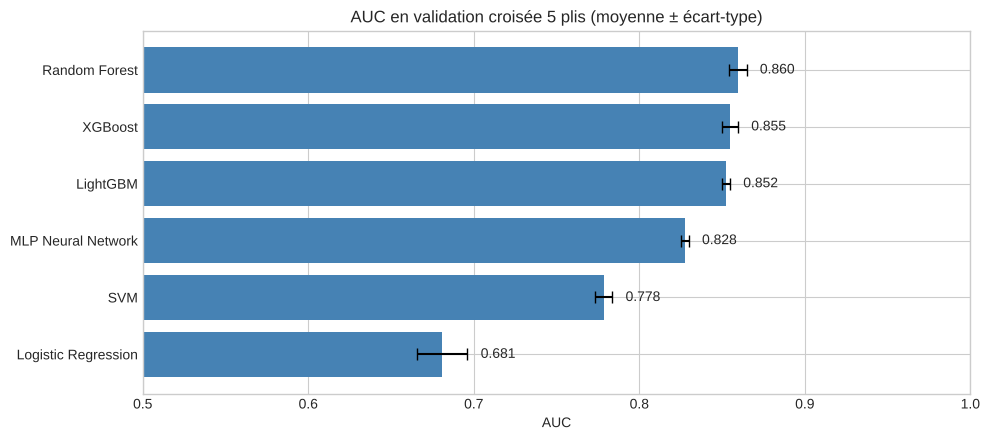

Meilleur modèle en validation croisée : Random Forest


In [14]:
fig, ax = plt.subplots(figsize=(10, 4.5))
order = cv_summary.index[::-1]
ax.barh(order, cv_summary.loc[order, "AUC (mean)"], xerr=cv_summary.loc[order, "AUC (std)"],
        color="steelblue", capsize=4)
for i, name in enumerate(order):
    mean, std = cv_summary.loc[name, ["AUC (mean)", "AUC (std)"]]
    ax.text(mean + std + 0.008, i, f"{mean:.3f}", va="center")
ax.set(title=f"AUC en validation croisée {CV_FOLDS} plis (moyenne ± écart-type)", xlabel="AUC", xlim=(0.5, 1.0))
plt.tight_layout()
save(fig, "cv_model_comparison.png")
plt.show()

best_name = cv_summary.index[0]
print(f"Meilleur modèle en validation croisée : {best_name}")

## IX. Optimisation des hyperparamètres du meilleur modèle

Recherche aléatoire évaluée sur les mêmes plis (les hyperparamètres de la version précédente étaient fixés à la main,
bien que le notebook mentionne un `GridSearchCV`). Les nouveaux hyperparamètres ne sont adoptés que s'ils améliorent l'AUC de validation croisée.

In [15]:
best_model = candidates[best_name]
best_params = None
search = None
if best_name in models.PARAM_DISTRIBUTIONS:
    search = evaluation.random_search(best_model, models.PARAM_DISTRIBUTIONS[best_name], folds,
                                      n_iter=N_SEARCH_ITER, random_state=RANDOM_STATE)
    display(search.drop(columns="params").head(5))
    if search.loc[0, "AUC (mean)"] > cv_summary.loc[best_name, "AUC (mean)"]:
        best_params = search.loc[0, "params"]
        best_model = clone(best_model).set_params(**best_params)
        _, oof_scores[best_name] = evaluation.cross_validate_model(best_model, folds)

print(f"AUC CV avant optimisation : {cv_summary.loc[best_name, 'AUC (mean)']:.4f}")
print(f"AUC CV après optimisation : {roc_auc_score(y_train, oof_scores[best_name]):.4f} (hors-pli)")
print(f"Hyperparamètres retenus   : {best_params or 'valeurs par défaut du projet'}")

,n_estimators,min_samples_split,min_samples_leaf,max_features,max_depth,AUC (mean),AUC (std)
0,500,2,2,0.3000,NaN,0.8608,0.0054
1,200,2,2,sqrt,30.0000,0.8602,0.0052
2,500,5,2,sqrt,NaN,0.8602,0.0050
3,200,5,2,0.5000,NaN,0.8598,0.0049
4,500,5,2,0.5000,NaN,0.8598,0.0053


AUC CV avant optimisation : 0.8596
AUC CV après optimisation : 0.8607 (hors-pli)
Hyperparamètres retenus   : {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 0.3, 'max_depth': None}


## X. Évaluation finale sur le jeu de test

Chaque modèle est réentraîné sur tout le train puis évalué **une seule fois** sur le test.
Les résultats des autres modèles sont donnés à titre de comparaison : ils n'ont pas servi au choix.

In [16]:
final_models = {name: (best_model if name == best_name else m) for name, m in candidates.items()}
fitted, test_rows, test_scores = {}, {}, {}
for name, model in final_models.items():
    fitted[name] = clone(model).fit(X_train_t, y_train)
    test_scores[name] = evaluation.predict_scores(fitted[name], X_test_t)
    test_rows[name] = evaluation.classification_metrics(y_test, test_scores[name], fitted[name].predict(X_test_t))

test_table = pd.DataFrame(test_rows).T.loc[cv_summary.index]
test_table

,AUC,Average Precision,F1-Score,Accuracy,Précision,Recall
Random Forest,0.8738,0.8275,0.8301,0.8279,0.8006,0.8618
XGBoost,0.8684,0.8233,0.8204,0.8163,0.7842,0.8602
LightGBM,0.8611,0.8141,0.8140,0.8069,0.7680,0.8659
MLP Neural Network,0.8343,0.7872,0.7828,0.7791,0.7523,0.8159
SVM,0.7847,0.7226,0.7027,0.7183,0.7242,0.6824
Logistic Regression,0.6705,0.6381,0.6072,0.6083,0.5945,0.6204


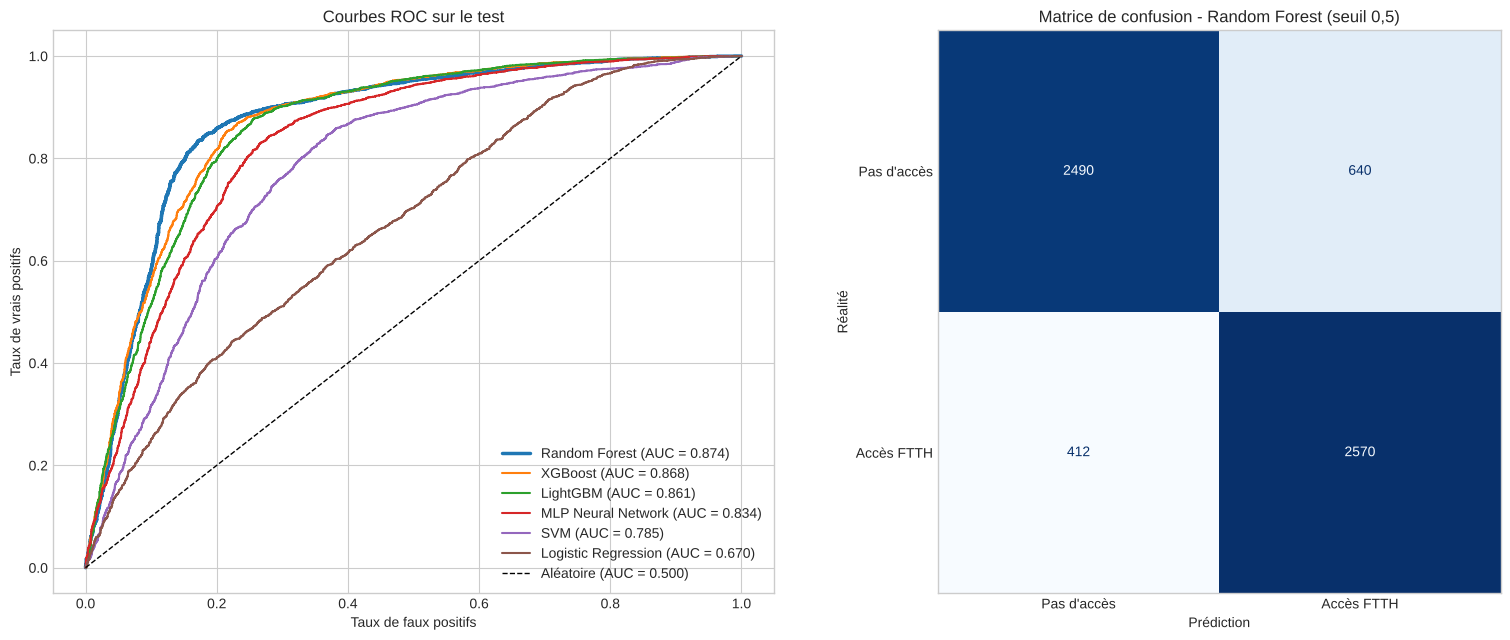

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for name in cv_summary.index:
    fpr, tpr, _ = roc_curve(y_test, test_scores[name])
    axes[0].plot(fpr, tpr, linewidth=2.5 if name == best_name else 1.5,
                 label=f"{name} (AUC = {test_table.loc[name, 'AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, label="Aléatoire (AUC = 0.500)")
axes[0].set(title="Courbes ROC sur le test", xlabel="Taux de faux positifs", ylabel="Taux de vrais positifs")
axes[0].legend(loc="lower right")

best_pred = fitted[best_name].predict(X_test_t)
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, display_labels=["Pas d'accès", "Accès FTTH"],
                                        cmap="Blues", values_format="d", ax=axes[1], colorbar=False)
axes[1].set(title=f"Matrice de confusion - {best_name} (seuil 0,5)", xlabel="Prédiction", ylabel="Réalité")
axes[1].grid(False)
plt.tight_layout()
save(fig, "roc_curves_comparison.png")
plt.show()

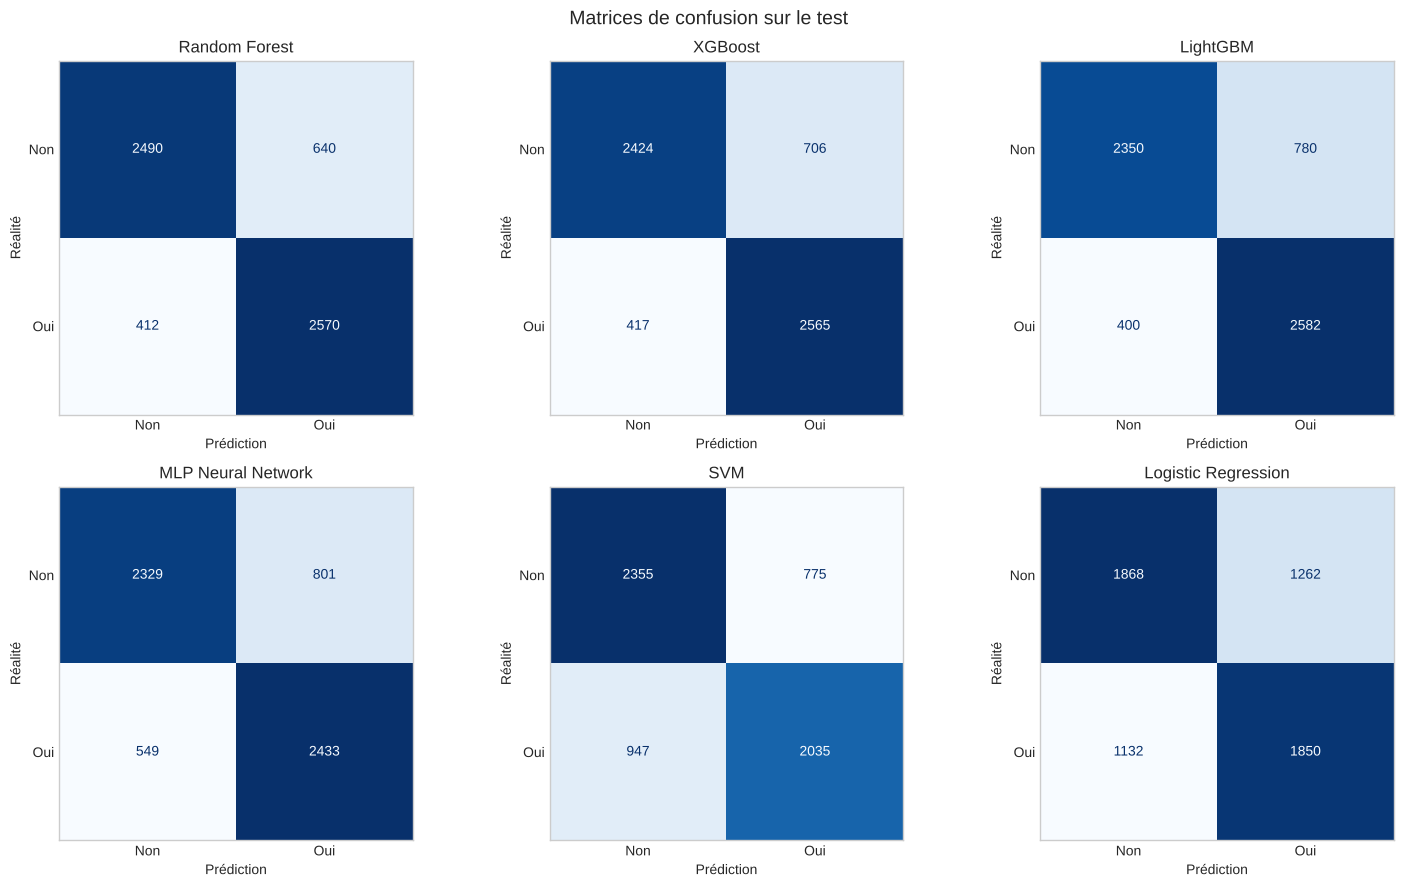

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, name in zip(axes.flat, cv_summary.index):
    ConfusionMatrixDisplay.from_predictions(y_test, fitted[name].predict(X_test_t), display_labels=["Non", "Oui"],
                                            cmap="Blues", values_format="d", ax=ax, colorbar=False)
    ax.set(title=name, xlabel="Prédiction", ylabel="Réalité")
    ax.grid(False)
fig.suptitle("Matrices de confusion sur le test", fontsize=14)
plt.tight_layout()
save(fig, "confusion_matrices.png")
plt.show()

In [19]:
# Pipeline final : prétraitement appris sur le train + meilleur modèle (avec probabilités).
final_model = train.with_probabilities(best_model)
final_model = fitted[best_name] if final_model is best_model else clone(final_model).fit(X_train_t, y_train)
pipeline = Pipeline([("preprocess", preprocessor), ("model", final_model)])

train_metrics = train.evaluate(pipeline, X_train, y_train)
test_metrics = train.evaluate(pipeline, X_test, y_test)
gap = pd.DataFrame({"Train": train_metrics, "Test": test_metrics})
gap["Écart"] = gap["Train"] - gap["Test"]
gap

,Train,Test,Écart
AUC,0.9867,0.8738,0.1129
Average Precision,0.9876,0.8275,0.1601
F1-Score,0.9256,0.8301,0.0955
Accuracy,0.9274,0.8279,0.0995
Précision,0.9253,0.8006,0.1247
Recall,0.9259,0.8618,0.0640


## XI. Robustesse géographique : que vaut le modèle sur une zone jamais vue ?

Presque tous les ménages du test appartiennent à une tuile déjà présente dans le train. Deux expériences permettent de mesurer
ce que le modèle apprend réellement :

1. **Référence naïve « taux de la tuile »** : chaque ménage du test reçoit le taux d'accès moyen observé dans sa tuile au train,
   sans aucun apprentissage.
2. **Validation croisée spatiale** (`StratifiedGroupKFold`, groupes = tuiles) : chaque pli de validation ne contient que des tuiles
   absentes de l'entraînement, comme lors d'un déploiement dans une nouvelle zone.

In [20]:
baseline_auc = train.tile_baseline_auc(ds)
print(f"AUC test - référence 'taux de la tuile' : {baseline_auc:.4f}")
print(f"AUC test - {best_name:28s}: {test_metrics['AUC']:.4f}")

spatial_cv = StratifiedGroupKFold(CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
spatial_folds = evaluation.make_folds(preprocessor, X_train, y_train, spatial_cv, ds.groups_train)
spatial_models = {name: final_models[name] for name in dict.fromkeys([best_name, "LightGBM", "Logistic Regression"])}
spatial_summary, _ = evaluation.cross_validate_models(spatial_models, spatial_folds)

robustness = pd.DataFrame({
    "AUC CV aléatoire": [cv_summary.loc[n, "AUC (mean)"] for n in spatial_summary.index],
    "AUC CV spatiale": spatial_summary["AUC (mean)"],
    "Écart-type spatial": spatial_summary["AUC (std)"],
}, index=spatial_summary.index)
if best_params:
    robustness.loc[best_name, "AUC CV aléatoire"] = roc_auc_score(y_train, oof_scores[best_name])

# Même modèle sans les composantes MOSAIKS : quelle est la valeur ajoutée des images satellites ?
no_mosaiks = f"{best_name} sans MOSAIKS"
robustness.loc[no_mosaiks, "AUC CV aléatoire"] = evaluation.cross_validate_model(
    best_model, evaluation.drop_features(folds, "mosaiks_pc"))[0]["AUC"].mean()
spatial_no_mosaiks = evaluation.cross_validate_model(best_model, evaluation.drop_features(spatial_folds, "mosaiks_pc"))[0]
robustness.loc[no_mosaiks, ["AUC CV spatiale", "Écart-type spatial"]] = [
    spatial_no_mosaiks["AUC"].mean(), spatial_no_mosaiks["AUC"].std()]
robustness

AUC test - référence 'taux de la tuile' : 0.8494
AUC test - Random Forest               : 0.8738


,AUC CV aléatoire,AUC CV spatiale,Écart-type spatial
Logistic Regression,0.6811,0.6622,0.0410
Random Forest,0.8607,0.6316,0.0769
LightGBM,0.8523,0.6178,0.0963
Random Forest sans MOSAIKS,0.6460,0.6080,0.0165


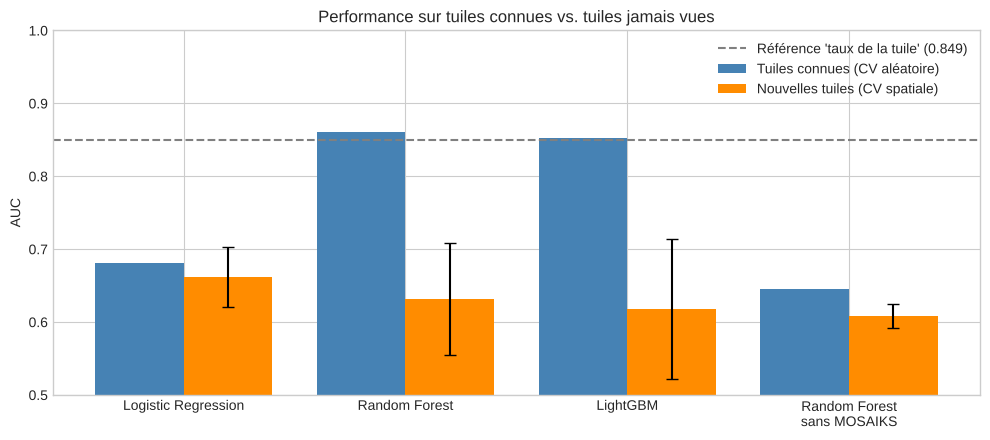

In [21]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(robustness))
ax.bar(x - 0.2, robustness["AUC CV aléatoire"], 0.4, label="Tuiles connues (CV aléatoire)", color="steelblue")
ax.bar(x + 0.2, robustness["AUC CV spatiale"], 0.4, yerr=robustness["Écart-type spatial"], capsize=4,
       label="Nouvelles tuiles (CV spatiale)", color="darkorange")
ax.axhline(baseline_auc, color="grey", linestyle="--", label=f"Référence 'taux de la tuile' ({baseline_auc:.3f})")
ax.set_xticks(x, [name.replace(" sans ", "\nsans ") for name in robustness.index])
ax.set(ylim=(0.5, 1.0), ylabel="AUC", title="Performance sur tuiles connues vs. tuiles jamais vues")
ax.legend(loc="upper right")
plt.tight_layout()
save(fig, "spatial_validation.png")
plt.show()

**Lecture**

- Sur le split officiel, le Random Forest (AUC 0,874) ne fait que **+0,024** de mieux que la simple moyenne du taux d'accès
  de la tuile (0,849) : l'essentiel de sa performance vient de la *reconnaissance* des tuiles déjà vues.
- Sur des **tuiles jamais vues**, l'AUC du Random Forest tombe à **~0,63** (avec une forte variabilité selon les plis).
  La régression logistique, plus simple, généralise mieux (~0,66) que les modèles d'arbres, qui mémorisent les tuiles.
- Sans les features MOSAIKS, le Random Forest obtient ~0,61 sur des tuiles nouvelles : pour une zone inconnue,
  les images satellites n'apportent que quelques points d'AUC.

Le modèle est donc adapté à la **priorisation de ménages dans des zones déjà enquêtées**, pas à la découverte de nouvelles zones.

## XII. Seuil de décision et fiabilité des probabilités

- Le seuil 0,5 est conservé pour les métriques officielles ; le seuil qui maximise le F1 est estimé sur les **prédictions hors-pli du train**
  (jamais sur le test) et indiqué à titre d'option.
- La courbe de calibration vérifie que les probabilités prédites correspondent aux fréquences observées.

Seuil F1-optimal (hors-pli train) : 0.446 -> test F1 = 0.8282, précision = 0.7812, rappel = 0.8813


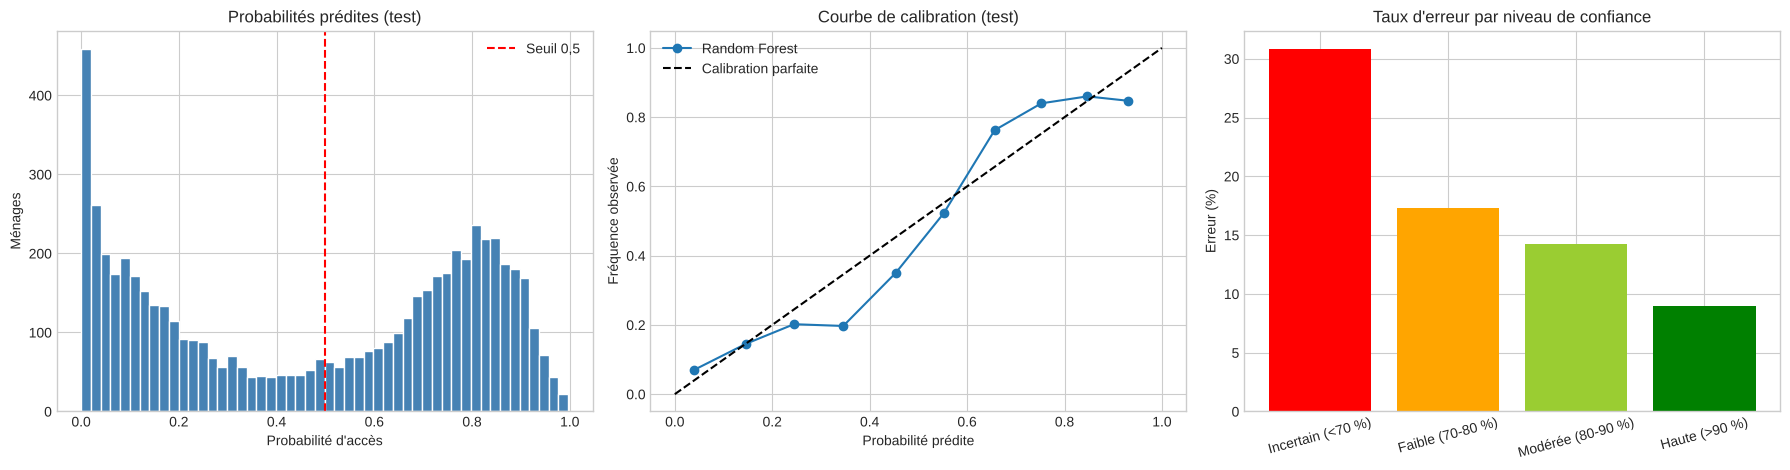

,Ménages,Taux_erreur
bucket,,
Incertain (<70 %),1397,0.3085
Faible (70-80 %),1297,0.1727
Modérée (80-90 %),1731,0.1421
Haute (>90 %),1687,0.0895


In [22]:
test_proba = pipeline.predict_proba(X_test)[:, 1]
threshold_f1 = evaluation.best_f1_threshold(y_train, oof_scores[best_name]) if hasattr(best_model, "predict_proba") else None
if threshold_f1 is not None:
    m = evaluation.classification_metrics(y_test, test_proba, (test_proba >= threshold_f1).astype(int))
    print(f"Seuil F1-optimal (hors-pli train) : {threshold_f1:.3f} -> test F1 = {m['F1-Score']:.4f}, "
          f"précision = {m['Précision']:.4f}, rappel = {m['Recall']:.4f}")

confidence = np.abs(test_proba - 0.5) * 2  # 0 = incertain, 1 = certain
buckets = pd.cut(confidence, [0, 0.4, 0.6, 0.8, 1.0], include_lowest=True,
                 labels=["Incertain (<70 %)", "Faible (70-80 %)", "Modérée (80-90 %)", "Haute (>90 %)"])
errors = pd.DataFrame({"bucket": buckets, "erreur": (test_proba >= 0.5) != y_test.to_numpy()})
error_table = errors.groupby("bucket", observed=False)["erreur"].agg(Ménages="size", Taux_erreur="mean")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].hist(test_proba, bins=50, color="steelblue", edgecolor="white")
axes[0].axvline(0.5, color="red", linestyle="--", label="Seuil 0,5")
axes[0].set(title="Probabilités prédites (test)", xlabel="Probabilité d'accès", ylabel="Ménages")
axes[0].legend()
frac_pos, mean_pred = calibration_curve(y_test, test_proba, n_bins=10)
axes[1].plot(mean_pred, frac_pos, "o-", label=best_name)
axes[1].plot([0, 1], [0, 1], "k--", label="Calibration parfaite")
axes[1].set(title="Courbe de calibration (test)", xlabel="Probabilité prédite", ylabel="Fréquence observée")
axes[1].legend()
axes[2].bar(error_table.index.astype(str), error_table["Taux_erreur"] * 100, color=["red", "orange", "yellowgreen", "green"])
axes[2].set(title="Taux d'erreur par niveau de confiance", ylabel="Erreur (%)")
axes[2].tick_params(axis="x", rotation=15)
plt.tight_layout()
save(fig, "uncertainty_analysis.png")
plt.show()
error_table

## XIII. Interprétabilité

### Importance des features (modèles à base d'arbres)

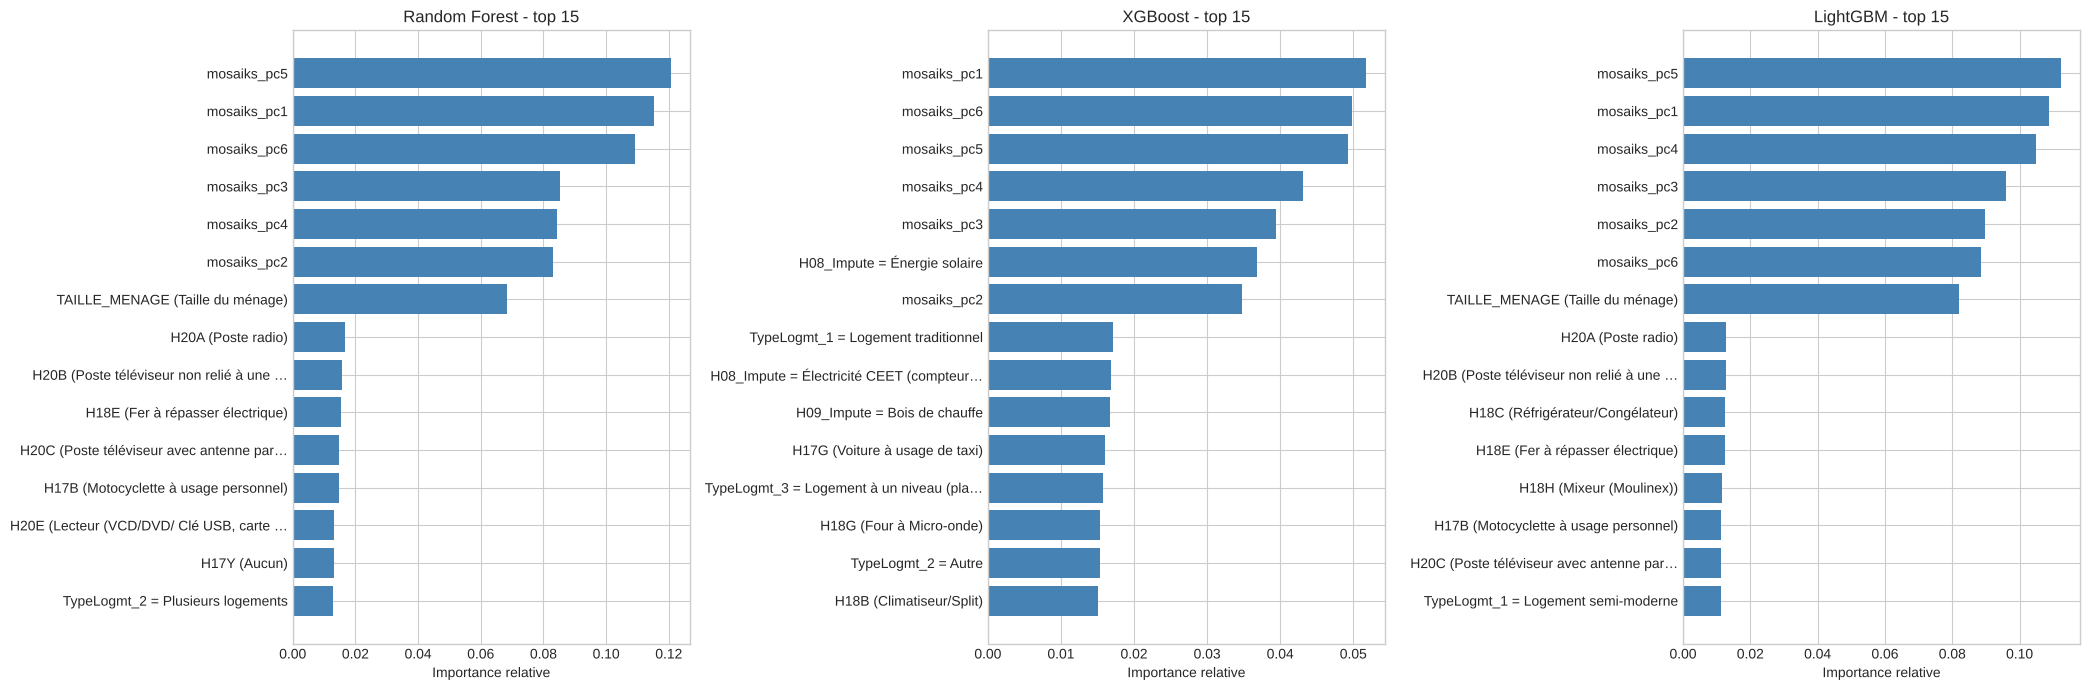

In [23]:
tree_models = [n for n in ["Random Forest", "XGBoost", "LightGBM"] if n in fitted]
fig, axes = plt.subplots(1, len(tree_models), figsize=(7 * len(tree_models), 7))
for ax, name in zip(np.atleast_1d(axes), tree_models):
    imp = pd.Series(fitted[name].feature_importances_, index=X_train_t.columns)
    imp = (imp / imp.sum()).sort_values().tail(15)
    ax.barh([display_name(c, width=40) for c in imp.index], imp.values, color="steelblue")
    ax.set(title=f"{name} - top 15", xlabel="Importance relative")
plt.tight_layout()
save(fig, "feature_importance_comparison.png")
plt.show()

### Valeurs SHAP
Les valeurs SHAP décomposent chaque prédiction en contributions de features. Elles sont calculées sur un échantillon reproductible
du test, avec les noms de features lisibles issus du pipeline.

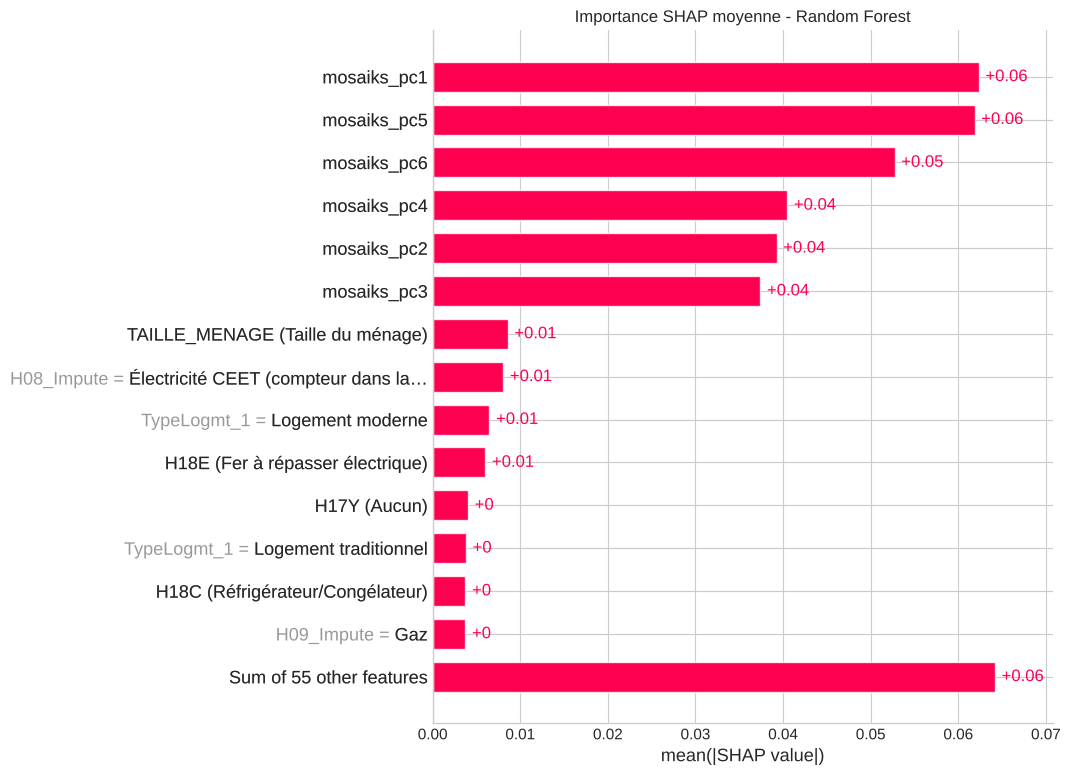

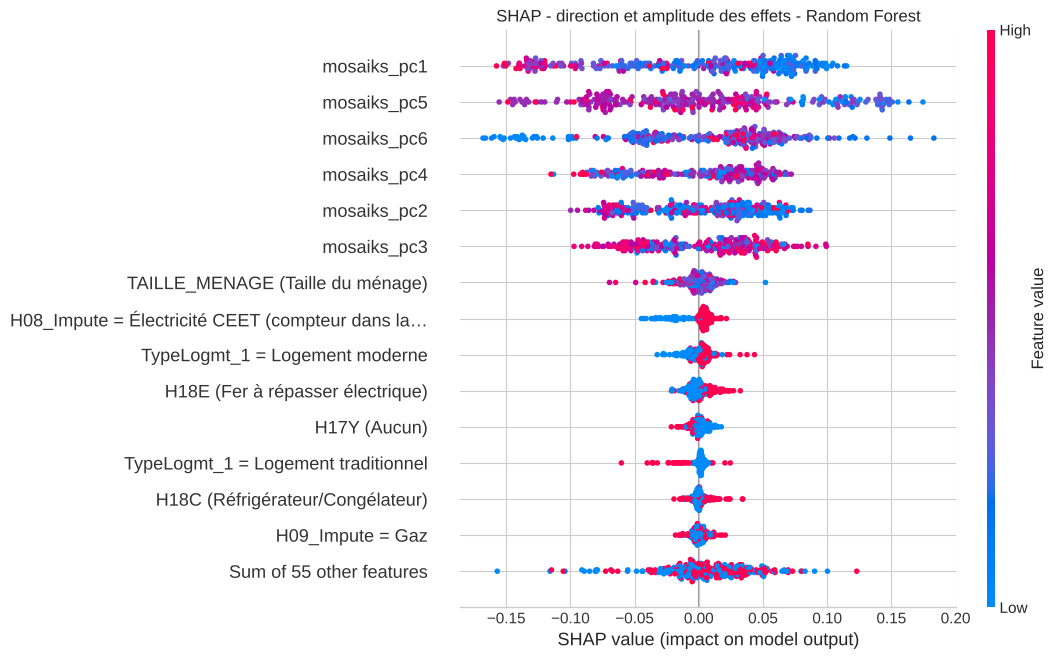

In [24]:
shap_model = fitted[best_name]
X_shap = X_test_t.sample(n=min(SHAP_SAMPLE, len(X_test_t)), random_state=RANDOM_STATE)
if best_name in tree_models:
    explainer = shap.TreeExplainer(shap_model)
else:  # modèle non arborescent : explainer générique avec un fond de 200 ménages du train
    explainer = shap.Explainer(shap_model, X_train_t.sample(200, random_state=RANDOM_STATE))
explanation = explainer(X_shap)
if explanation.values.ndim == 3:  # classifieurs qui renvoient une sortie par classe
    explanation = explanation[:, :, 1]
explanation = shap.Explanation(values=explanation.values, base_values=explanation.base_values,
                               data=explanation.data, feature_names=[display_name(c) for c in X_shap.columns])

plt.figure()
shap.plots.bar(explanation, max_display=15, show=False)
plt.title(f"Importance SHAP moyenne - {best_name}")
save(plt.gcf(), "shap_importance.png")
plt.show()

plt.figure()
shap.plots.beeswarm(explanation, max_display=15, show=False)
plt.title(f"SHAP - direction et amplitude des effets - {best_name}")
save(plt.gcf(), "shap_beeswarm.png")
plt.show()

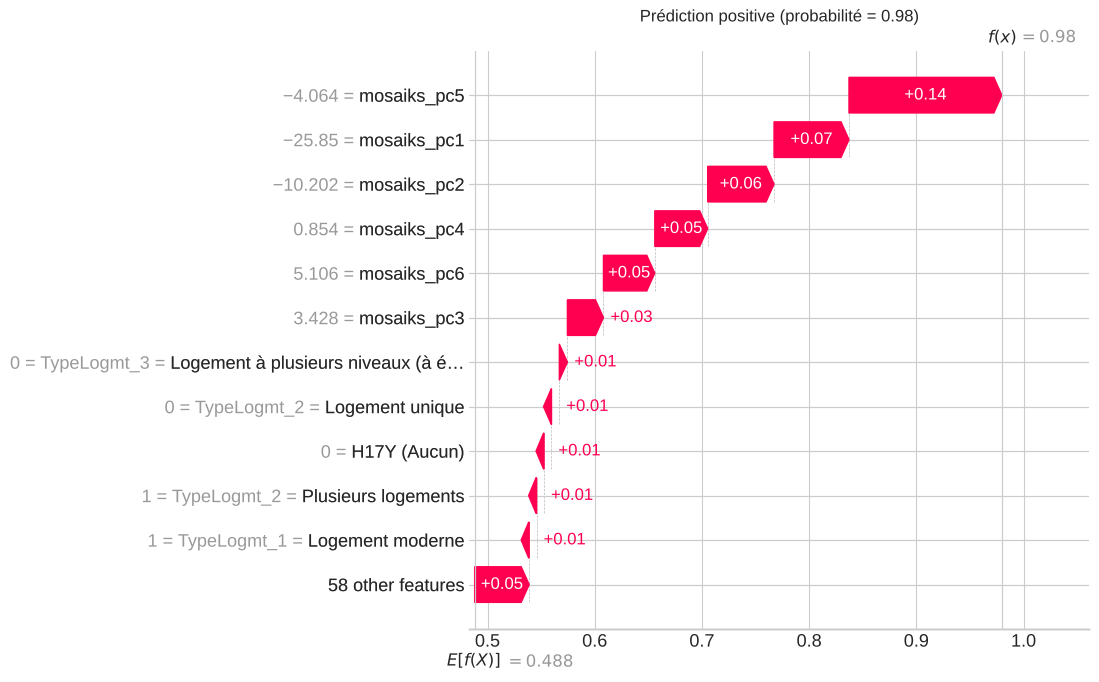

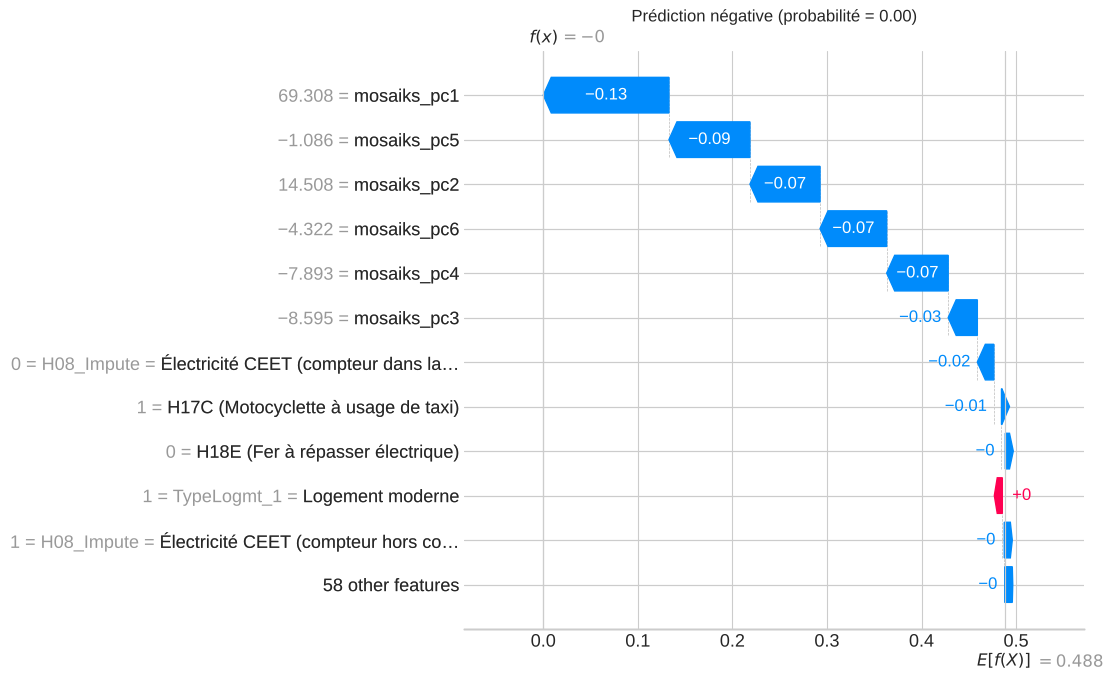

In [25]:
shap_proba = shap_model.predict_proba(X_shap)[:, 1]
for label, idx, fname in [("positive", int(np.argmax(shap_proba)), "shap_waterfall_positive.png"),
                          ("négative", int(np.argmin(shap_proba)), "shap_waterfall_negative.png")]:
    plt.figure()
    shap.plots.waterfall(explanation[idx], max_display=12, show=False)
    plt.title(f"Prédiction {label} (probabilité = {shap_proba[idx]:.2f})")
    save(plt.gcf(), fname)
    plt.show()

**Lecture** : les six composantes MOSAIKS (le « profil » de la tuile) dominent les contributions, puis viennent la taille du ménage,
le raccordement électrique dans la concession, le type de logement et les équipements. Ces effets décrivent des **associations**
apprises par le modèle, pas des relations de cause à effet.

## XIV. Export

- `Output/models/ftth_pipeline.joblib` : **pipeline complet** (prétraitement + modèle) directement applicable à de nouvelles données
  brutes avec `ftth-predict` (non versionné, régénéré par ce notebook ou par `ftth-train`) ;
- `Output/predictions_test.csv` : prédictions sur le test avec les **ID d'origine** ;
- `Output/model_comparison.csv` et `Output/rapport_modele.json` : comparaison et rapport complet.

In [26]:
predictions = train.prediction_table(ds.ids_test, test_proba, y_true=y_test)
report = train.build_report(
    ds, best_name, best_params, cv_summary, spatial_summary, train_metrics, test_metrics,
    threshold_f1, baseline_auc, preprocessor.get_feature_names_out().tolist(),
)
train.save_artifacts(OUTPUT_DIR, pipeline, best_name, X_train.columns, cv_summary, predictions, report)

levels = predictions.groupby("Niveau_Potentiel", observed=False).agg(
    Ménages=("ID", "size"), Taux_accès_réel=("Valeur_Réelle", "mean")
)
display(levels)
predictions.head()

,Ménages,Taux_accès_réel
Niveau_Potentiel,,
Faible,2213,0.1062
Moyen,689,0.2569
Élevé,1291,0.7266
Très élevé,1919,0.8504


,ID,Valeur_Réelle,Probabilité_Accès,Prédiction,Niveau_Potentiel
0,ID_54MT5I8EPC,0,0.6008,1,Élevé
1,ID_DGZQVLNITN,0,0.5577,1,Élevé
2,ID_S1ZGN8MORQ,1,0.7032,1,Élevé
3,ID_IBZA5NO9F5,0,0.0745,0,Faible
4,ID_DS6DHIDC5M,1,0.8128,1,Très élevé


In [27]:
# Vérification : le modèle exporté se recharge et s'applique à des données brutes.
from ftth_access import predict

bundle = predict.load_bundle()
sample_raw = data.load_raw().sample(5, random_state=RANDOM_STATE).drop(columns=[TARGET_COL])
predict.predict_frame(bundle, sample_raw)

,ID,Probabilité_Accès,Prédiction,Niveau_Potentiel
0,ID_N259G6APBB,0.0381,0,Faible
1,ID_8GMX7P0G3D,0.6972,1,Élevé
2,ID_8PB4DK6805,0.0355,0,Faible
3,ID_UHGE5L43I9,0.8916,1,Très élevé
4,ID_O0SQKW5LQI,0.9612,1,Très élevé


In [28]:
print(f"Modèle retenu : {best_name}")
for k in ["AUC", "F1-Score", "Accuracy", "Précision", "Recall"]:
    print(f"  Test {k:10s}: {test_metrics[k]:.4f}")
print(f"  AUC sur tuiles jamais vues (CV spatiale) : {spatial_summary.loc[best_name, 'AUC (mean)']:.4f}")
print("\nFichiers dans Output/ :")
for path in sorted(OUTPUT_DIR.glob("*")):
    if path.is_file():
        print(f"  {path.name:38s} {path.stat().st_size / 1024:8.1f} Ko")

Modèle retenu : Random Forest
  Test AUC       : 0.8738
  Test F1-Score  : 0.8301
  Test Accuracy  : 0.8279
  Test Précision : 0.8006
  Test Recall    : 0.8618
  AUC sur tuiles jamais vues (CV spatiale) : 0.6316

Fichiers dans Output/ :
  confusion_matrices.png                    124.8 Ko
  cv_model_comparison.png                    55.9 Ko
  feature_importance_comparison.png         288.1 Ko
  model_comparison.csv                        1.7 Ko
  mosaiks_pca_visualization.png             179.9 Ko
  pca_variance.png                           89.4 Ko
  predictions_test.csv                      277.9 Ko
  rapport_modele.json                         8.5 Ko
  roc_curves_comparison.png                 195.8 Ko
  shap_beeswarm.png                         291.2 Ko
  shap_importance.png                       160.3 Ko
  shap_waterfall_negative.png               163.5 Ko
  shap_waterfall_positive.png               156.8 Ko
  spatial_validation.png                     64.1 Ko
  target_distribution

## XV. Conclusions et recommandations

### Synthèse des résultats

- Six modèles ont été comparés en validation croisée 5 plis sur le train. Le **Random Forest** arrive en tête
  (AUC 0,860 ± 0,005), devant XGBoost (0,855) et LightGBM (0,852) ; le MLP (0,828), le SVM (0,778) et la régression
  logistique (0,681) sont nettement derrière.
- Après optimisation (500 arbres, `max_features=0.3`), l'évaluation unique sur le test donne **AUC 0,874, F1 0,830,
  précision 0,801, rappel 0,862**.
- Les probabilités sont exploitables pour prioriser : **85 %** des ménages classés « Très élevé » ont effectivement la fibre,
  contre **11 %** des ménages classés « Faible » ; le taux d'erreur passe de 31 % pour les prédictions incertaines à 9 %
  pour les prédictions de haute confiance.

### Enseignements clés

1. **La zone géographique domine.** Les 30 558 ménages ne couvrent que 423 tuiles satellites ; le taux d'accès moyen de la
   tuile suffit à atteindre une AUC de 0,849.
2. **Les variables socio-démographiques affinent sans suffire.** Leurs corrélations avec la cible restent faibles
   (|r| ≤ 0,15) et, seules, elles plafonnent à une AUC de ~0,65.
3. **La généralisation à de nouvelles zones est faible** (AUC ~0,63 sur des tuiles jamais vues) ; un modèle plus simple
   (régression logistique, ~0,66) s'y comporte mieux.
4. **Le Random Forest surapprend** (AUC 0,987 sur le train contre 0,874 sur le test), sans que cela dégrade le test :
   c'est attendu pour ce type de modèle, mais cela confirme qu'il mémorise les tuiles.

### Recommandations

1. **Usage recommandé** : prioriser les ménages *dans des zones déjà enquêtées* (campagnes commerciales ciblées,
   programmes d'accompagnement des ménages à faible potentiel).
2. **Nouvelles zones** : ne pas utiliser ce modèle seul. Sélectionner le modèle par validation spatiale et ajouter des
   données transférables (coordonnées, distance au réseau existant, densité de bâti, données d'infrastructure).
3. **Seuil de décision** : 0,5 par défaut ; un seuil de 0,446 (estimé hors-pli) maximise le F1 et porte le rappel à 0,881
   si l'objectif est de ne pas manquer de ménages raccordables.
4. **Probabilités** : les probabilités élevées sont légèrement surestimées (0,93 prédit pour 0,85 observé) ; les calibrer
   avant de s'en servir pour estimer des volumes.

### Limites

- Données statiques (pas de dimension temporelle) et sans variable régionale : l'équité urbain/rural ne peut pas être auditée.
- Résolution MOSAIKS grossière (423 tuiles) : l'information satellite est un descripteur de zone, pas de ménage.
- Les relations mises en évidence (SHAP, corrélations) sont des associations, pas des causes.